In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import numpy as np
import torch
from imlff.common.util import proj_path
from imlff.data.util import load_md17_data
from imlff.loading import load_model_from_wandb
from imlff.analysis.cumulene import style, annotate, \
    plot_E_per_atom, plot_E_per_molecule, get_indices_sel, get_Z, get_model_tag, mae_per_molecule
from imlff.analysis.cumulene_loading import load_or_calc, load_prep_model
import numpy as np
from ase import Atoms

import matplotlib as mpl
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from nglview import show_asetraj, show_ase
from tqdm import tqdm

     
from matplotlib.ticker import MultipleLocator, FuncFormatter

    
symbols = {1:'H', 6:'C'}
fig_path = proj_path('figures/')

In [6]:
## uncomment to install heatmap:
# !python -m pip install cmcrameri

try:
    cmap = 'cmc.batlow'
    import cmcrameri # (for availability of the colormap)
    assert cmap in plt.colormaps()
except:
    cmap = 'cividis'
    print(f'fallig back to {cmap}. have you installed and imported cmcrameri?')

# Overview

In [4]:
for i in range(1,9):
    mol = f'cumulene{i}_test'
    path = proj_path(f'data/Cumulene/{mol}.npz', verbose=False)
    data = np.load(path)
    print(f"'{mol}': {len(data['F'])},")

'cumulene1_test': 1000,
'cumulene2_test': 1000,
'cumulene3_test': 1000,
'cumulene4_test': 1000,
'cumulene5_test': 1000,
'cumulene6_test': 1000,
'cumulene7_test': 1000,
'cumulene8_test': 1000,


In [4]:
from ase import Atoms
from nglview import show_asetraj

i = 8
path = proj_path(f'data/Cumulene/cumulene{i}_train.npz', verbose=False)
data = np.load(path)
for k, v in data.items():
    print(k, v.shape if len(v.shape) > 0 else v)

# build list of ASE Atoms (one per conformation in R)
atoms_list = [Atoms(positions=R, numbers=data['z']) for R in data['R']]

show_asetraj(atoms_list)


type d
code_version 0.4.1
name mndo-cumulene8_train
theory GFN2-xTB
R (4973, 13, 3)
z (13,)
F (4973, 13, 3)
F_min -14.591983
F_max 16.911116
F_mean -5.8514565e-10
F_var 5.1031494
r_unit Ang
e_unit eV
E (4973, 1)
E_min -65.89037
E_max -61.316418
E_mean -64.38474
E_var 0.37887073
md5 np.bytes_(b'fd701a583c3581be0717887bede31a75')


NGLWidget(max_frame=4972)

# Dataset Overview

<Figure size 800x600 with 0 Axes>

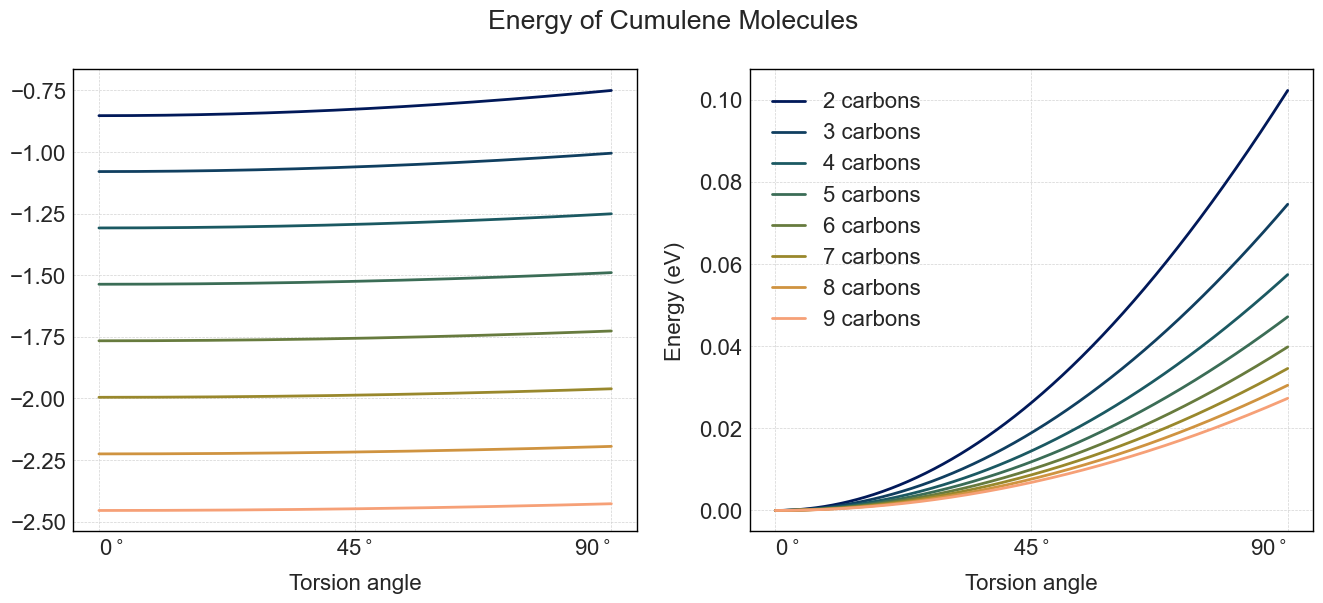

In [10]:
diff = True
n_molecules = 9
hartree = True

plt.figure(figsize=(8, 6))
style(n_lines=n_molecules, cmap=cmap)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for diff, ax in zip([False, True], axs):

    for molecule_i in range(1, n_molecules):
        path = proj_path(f'data/Cumulene/cumulene{molecule_i}_test.npz', verbose=False)
        data = np.load(path)['E']
        if diff:
            data -= data[0]
            
        if hartree:
            data *= 0.0367493
        ax.plot(data, label=f'{molecule_i+1} carbons')
        
    if diff:
        ax.legend()
    annotate(ax, ylabel=diff)

fig.suptitle('Energy of Cumulene Molecules')
plt.show()

# Visualization

In [97]:
molecule_i=1
molecule_i=2
# molecule_i=3
# molecule_i=4
# molecule_i=8

path = proj_path(f'data/Cumulene/cumulene{molecule_i}_test.npz', verbose=False)
# path = proj_path(f'data/Cumulene/cumulene{molecule_i}_train.npz', verbose=False)

data = np.load(path)
# print('N atoms:', len(data['z']))

until = -2
until = 1000

atoms_list = [Atoms(positions=R[:until], numbers=data['z'][:until]) for R in data['R']]
show_asetraj(atoms_list)

NGLWidget(max_frame=999)

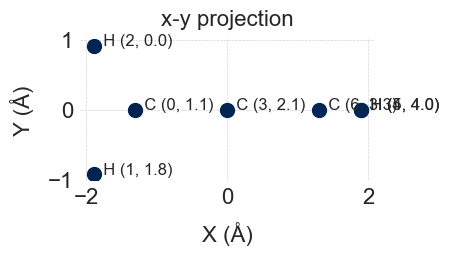

In [99]:

conformation_i = -1
conformation_i = 0
R = data['R'][conformation_i]
Z = data['z']
style(len(Z))
style(256)

# Plot the points
h = max(R[:, 1]) - min(R[:, 1])
w = max(R[:, 0]) - min(R[:, 0])
plt.figure(figsize=(w, h))

distance = np.linalg.norm(R[2] - R, axis=1)
# distance = None

for idx, (x, y) in enumerate(R[:, :2]):
    dist =  f', {distance[idx]:.1f}' if distance is not None else ''
    label = f'{symbols[Z[idx]]} ({idx}{dist})'
    plt.scatter(x, y, s=100)
    plt.text(x, y, f'  {label}', fontsize=12)
    
plt.xlabel('X (Å)')
plt.ylabel('Y (Å)')
plt.title('x-y projection')
for edge in ['top', 'right', 'left', 'bottom']:
    plt.gca().spines[edge].set_visible(False)
plt.show()

- 1.6 is smaller than the distance between any unbonded atoms
- 1.8 is distance between hydrogens within ExceptionGroup
- 3.1 covers entire 2C cumulene
- 2.1 reaches from C to all H in 2C
- 11.5 covers entire C9 cumulene


# E dataset prediction

In [ ]:
for type in ['imp', 'exp-3']:
    for cutoff in [
        5.,
        1.75,
        12.,
    ]:
    for molecule_i in range(1, 9):
        print('='*40, molecule_i, '='*40)
        load_or_calc(Rep='SO3Net', type=type,
                     model_i=(1,2,3,4,5),
                    #  model_i=(1,2,3,4,5,6,7,8),
                     cutoff=5., molecule_i=molecule_i)

In [28]:
nnpot = None

In [ ]:
from imlff.analysis.cumulene import load_prep_model
model_tag = 'qcml-group/dev-v10/model-tnyqj9i3:v219' # unfinished
per_atom_output_key = 'energy_per_atom'
nnpot = nnpot or load_prep_model(model_tag, per_atom_output_key)

~/imlff/models/qcml-group/dev-v10/model-tnyqj9i3:v219/model.ckpt
Loaded model from ~/imlff/models/qcml-group/dev-v10/model-tnyqj9i3:v219/model.ckpt with cpu device


/Users/johannes/miniconda3/envs/schnet/lib/python3.12/site-packages/pytorch_lightning/utilities/migration/utils.py:56: The loaded checkpoint was produced with Lightning v2.5.0.post0, which is newer than your current Lightning version: v2.4.0
/Users/johannes/miniconda3/envs/schnet/lib/python3.12/site-packages/pytorch_lightning/utilities/parsing.py:208: Attribute 'model' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['model'])`.


In [12]:
# LEARNING ON ALL #

substract_start=True

extrapolation = False

models = [
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=12.,
            model_i=(1,2,3,4,5,6,7,8),
            norm=False,
        ),
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=5.,
            model_i=(1,2,3,4,5,6,7,8),
            norm=True,
        ),
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=1.75,
            model_i=(1,2,3,4,5,6,7,8),
            norm=False,
        ),
        
        # # # Explicit
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=12.,
            model_i=(1,2,3,4,5,6,7,8),
        ),
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=5.,
            model_i=(1,2,3,4,5,6,7,8),
        ),
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=1.75,
            model_i=(1,2,3,4,5,6,7,8),
        ),
        dict(
            Rep='SO3Net',
            type='exp-6',
            cutoff=5.,
            model_i=(1,2,3,4,5,6,7,8),
        ),
    ]

In [13]:
# EXTRAPOLATION

extrapolation = True

jac_reg=None
jac_reg=0.32

substract_start = True

models = [
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=12.,
            model_i=(1,2,3,4,5),
            norm=True,
        ),
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=5.,
            model_i=(1,2,3,4,5),
            norm=True,
        ),
        dict(
            Rep='SO3Net',
            type='imp',
            cutoff=1.75,
            model_i=(1,2,3,4,5),
            norm=True,
        ),
        
        # Explicit
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=12.,
            model_i=(1,2,3,4,5),
            norm=False,
        ),
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=5.,
            model_i=(1,2,3,4,5),
            norm=False,
        ),
        dict(
            Rep='SO3Net',
            type='exp-3',
            cutoff=1.75,
            model_i=(1,2,3,4,5),
            norm=False,
        ),
        dict(
            Rep='SO3Net',
            type='exp-6',
            cutoff=5.,
            model_i=(1,2,3,4,5),
            norm=False,
        ),
    ]

In [ ]:
df = mae_per_molecule(models)

In [ ]:
# Chemical accuracy: 1 kcal/mol = 0.0434 eV (same yardstick reused for forces, eV/Ang).
CHEM_ACC_EV = 1 / 23.060541945329334  # kcal/mol -> eV

_TYPE_PRETTY = {'imp': 'Implicit', 'exp-3': 'Explicit', 'exp-6': 'Explicit-6'}

def _fmt_cutoff(c):
    # trim trailing zeros: 12.0 -> 12, 5.0 -> 5, 1.75 -> 1.75
    s = f'{c:g}'
    return s

def _prettify(tbl):
    # pretty row index (Cutoff / Type) and molecule column labels (C_nH_4)
    t = tbl.copy()
    cutoffs = [_fmt_cutoff(c) for c in t.index.get_level_values(0)]
    types = [_TYPE_PRETTY.get(x, x) for x in t.index.get_level_values(1)]
    import pandas as pd
    t.index = pd.MultiIndex.from_arrays([cutoffs, types], names=['Cutoff', 'Type'])
    t.columns = [f'C<sub>{m + 1}</sub>H<sub>4</sub>' for m in t.columns]
    t.columns.name = None
    return t

def _chem_acc_style(col, acc=CHEM_ACC_EV):
    # ABSOLUTE: green <=1x chem acc, yellow <=3x, red beyond
    out = []
    for r in (col / acc):
        if r <= 1:
            out.append('background-color: #c6efce; color: #006100')
        elif r <= 3:
            out.append('background-color: #ffeb9c; color: #9c6500')
        else:
            out.append('background-color: #ffc7ce; color: #9c0006')
    return out

def _ratio_to_min_style(tbl, red_at=3.0):
    # RELATIVE: per molecule column, per cutoff group (index level 0), shade each
    # cell by value / (group min). 1x -> green, >= red_at x -> full red (log).
    import numpy as np
    import matplotlib.colors as mcolors
    cmap = mcolors.LinearSegmentedColormap.from_list(
        'g2r', ['#c6efce', '#ffeb9c', '#ffc7ce'])
    out = tbl.copy().astype(object)
    cutoffs = tbl.index.get_level_values(0)
    for col in tbl.columns:
        vals = tbl[col]
        for cut in cutoffs.unique():
            grp = vals[(cutoffs == cut)]
            gmin = grp.min()
            for idx, v in grp.items():
                if gmin is None or gmin <= 0 or v != v:  # nan-safe
                    out.loc[idx, col] = ''
                    continue
                t = min(max(np.log(v / gmin) / np.log(red_at), 0.0), 1.0)
                r, g, b, _ = cmap(t)
                fg = '#000000' if t < 0.5 else '#9c0006'
                out.loc[idx, col] = f'background-color: {mcolors.to_hex((r, g, b))}; color: {fg}'
    return out

def _mae_pivot(metric):
    # rows = model (cutoff, type), columns = molecule_i
    return (df.pivot_table(index=['cutoff', 'type'], columns='molecule_i',
                           values=metric, aggfunc='first'))

# styling: 'abs' = vs chemical accuracy, 'rel' = vs per-molecule per-cutoff best
STYLE = 'abs'
# STYLE = 'rel'

def _style_tbl(tbl, what, unit):
    tbl = _prettify(tbl)
    s = tbl.style.format('{:.4f}').format_index(escape=None, axis=1)
    if STYLE == 'rel':
        s = s.apply(lambda t: _ratio_to_min_style(t), axis=None)
        cap = f'{what} MAE [{unit}]  -  per molecule, per cutoff: green = group best, red = >=3x best'
    else:
        s = s.apply(_chem_acc_style)
        cap = (f'{what} MAE [{unit}]  -  green <=1x, yellow <=3x, '
               f'red >3x chemical accuracy ({CHEM_ACC_EV*1000:.1f} meV)')
    return s.set_caption(cap)

e_tbl = _mae_pivot('energy_MAE')
_style_tbl(e_tbl, 'Energy', 'eV')


In [16]:
f_tbl = _mae_pivot('forces_MAE')
_style_tbl(f_tbl, 'Force', 'eV/Ang')


Info: returning model with jac_reg=0.32 (model_i=(1,2,3,4,5), cutoff=12., 18mj6p3w)
Info: returning model with jac_reg=0.32 (model_i=(1,2,3,4,5), cutoff=1.75, n6hbbe5x)


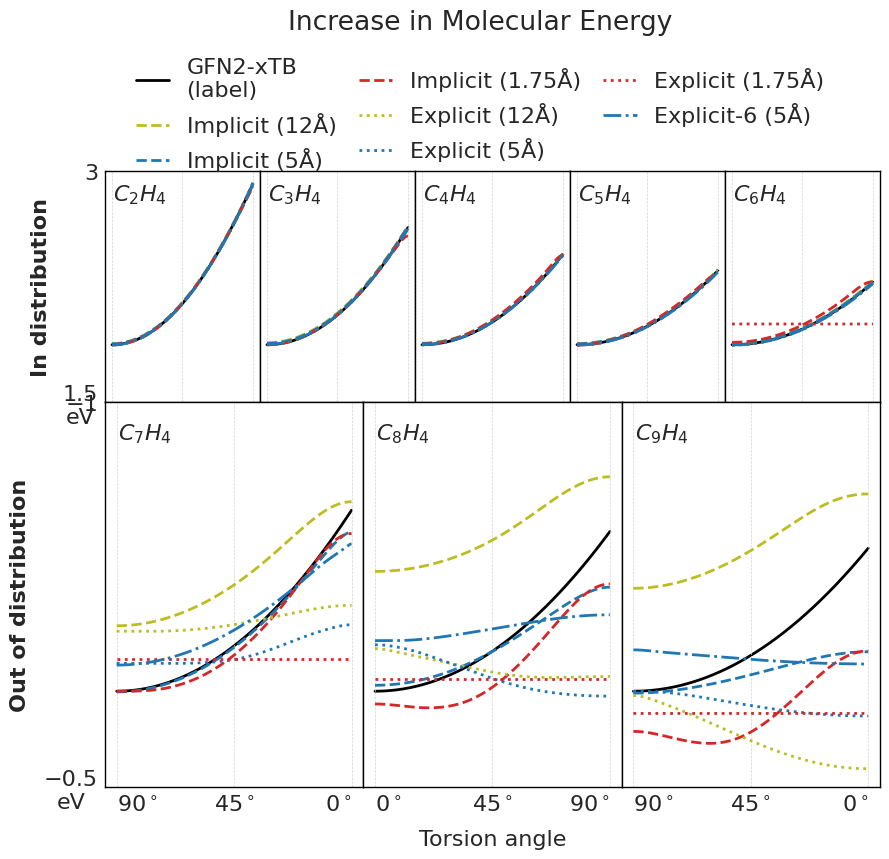

In [ ]:
## PAPER PLOT - MOLECULAR ENERGY EXTRAPOLATION ##

import matplotlib.pyplot as plt
import numpy as np
import math

if extrapolation:
    fig = plt.figure(figsize=(10, 8))
    gs = fig.add_gridspec(
        2, 15, hspace=0, wspace=0,
        height_ratios=[1, 5/3]  # 5 axes in row 1, 3 in row 2 → 1 : 5/3 height ratio
    )

    r1 = [fig.add_subplot(gs[0, i*3:(i+1)*3]) for i in range(5)]
    r2 = [fig.add_subplot(gs[1, i*5:(i+1)*5]) for i in range(3)]
else:
    fig = plt.figure(figsize=(8, 6))
    gs = fig.add_gridspec(
        2, 4, hspace=0, wspace=0,
    )

    r1 = [fig.add_subplot(gs[0, i:(i+1)]) for i in range(4)]
    r2 = [fig.add_subplot(gs[1, i:(i+1)]) for i in range(4)]
    # 

axs = r1 + r2

plot_E_per_molecule(models=models, axs=axs, tied=False, legend=False, substract_start=substract_start, plot_label=True, add_offsets=True, cmap='gist_rainbow', verbose=0)

for ax in axs:
    title = ax.get_title().split(' ')[0]
    ax.set_title("")  # remove default title
    ax.text(0.05, 0.95, title, transform=ax.transAxes,
            ha='left', va='top', fontsize='medium')
    ax.set_xlabel('')
r2[1].set_xlabel('Torsion angle')
    
for ax in r1:
    ax.tick_params(axis='x', left=False, bottom=False, labelleft=False, labelbottom=False)
if substract_start:
    for r, interval in ([r1, 1.], [r2, .5]):
        for ax in r[1:]:
            ax.sharey(r[0])
            ax.tick_params(axis='y', left=False, bottom=False, labelleft=False, labelbottom=False)
            
        ax = r[0]
        ymin, ymax = ax.get_ylim()
        
        inv = 1.0 / interval
        start = np.floor(ymin * inv) / inv
        stop = np.ceil(ymax * inv) / inv
        ts = np.arange(start, stop + interval * 0.01, interval)
        ts = ts[(ts>=0) ^ (ts<.9*ymax)]
        ax.set_yticks(ts)
        
        lbls = [f"{t}\neV" for t in ts]
        ax.set_yticklabels(lbls)
        
        # Center each line of the multiline tick labels
        for lbl in ax.get_yticklabels():
            lbl.set_multialignment('center')
        

# add 'eV' to each text:
lbls = r2[0].get_yticklabels()
r2[0].set_yticklabels(lbls)
# Center each line of the multiline tick labels
for lbl in r2[0].get_yticklabels():
    # lbl.set_ha('center')
    lbl.set_multialignment('center')

if extrapolation:
    handles, labels = r1[0].get_legend_handles_labels()
    ncols = min(3, len(handles))
    nrows = math.ceil(len(handles) / ncols)
    fig.legend(handles, labels, loc='upper center', ncol=ncols, bbox_to_anchor=(0.5, 0.9+0.05*nrows))
        
    # tit = "Molecular Energy (relative to relaxed, in eV)"
    # fig.text(0.01, 0.5, tit, va='center', rotation='vertical', fontsize='large')
    tit = "Increase in Molecular Energy"
    fig.text(0.5, .9+.05*nrows, tit, va='bottom', ha='center', fontsize='large')
    r1[0].set_ylabel("In distribution", fontweight='bold')
    r2[0].set_ylabel("Out of distribution", fontweight='bold')
else:
    r1[0].set_ylabel('')
    r2[0].set_ylabel("Training on all molecules", fontweight='bold')
    

fig.savefig(fig_path+"cumulene_molecular_energy_plot" + extrapolation*"_extrapolation" + ".pdf", bbox_inches='tight')
